# Můžu letět?, pokročilá verze: jak přesný je model, profil větru a létavé hodiny

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/drone_weather_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Můžu letět? Počasí pro drony](https://openskylab.space/edu_viz_drone_weather.html) · [English version](drone_weather_pro_en.ipynb)

Pokročilá verze notebooku o počasí pro drony. Modelovou předpověď Open-Meteo porovnáš s týdnem skutečných zpráv METAR ze čtyř českých letišť a spočítáš, jak moc se model plete ve větru, teplotě a rosném bodu. Pak z tří měsíců modelových dat pro Roztoky zjistíš, jak se mění profil větru se stabilitou ovzduší během dne a ve kterých hodinách se dalo létat nejčastěji.

**Cíl:** dekódovat týden zpráv METAR, ověřit proti nim model (odchylka, RMSE, korelace), spočítat exponent profilu větru a jeho závislost na teplotním zvrstvení a sestavit denní chod podílu hodin vhodných k letu podle větru, nárazů, srážek, dohlednosti a námrazy.

**Data:** zprávy METAR za posledních 7 dní z letišť Praha (LKPR), Brno (LKTB), Ostrava (LKMT) a Karlovy Vary (LKKV) ze služby NOAA Aviation Weather Center; hodinová data Open-Meteo za stejných 7 dní pro souřadnice letišť a za 92 dní pro Roztoky (vítr v 10, 80 a 120 m, nárazy, teplota ve 2 a 120 m, rosný bod, srážky, dohlednost). Hodnoty Open-Meteo pro minulé dny jsou uložené krátkodobé předpovědi modelů, ne měření. Data se průběžně mění, tvoje čísla budou jiná než v uloženém notebooku.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 50 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava

In [1]:
import re, time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

## 2. Týden zpráv METAR

Stáhneme zprávy za 7 dní, dekódujeme vítr, nárazy, teplotu, rosný bod, dohlednost a základnu oblačnosti a ponecháme jednu zprávu na hodinu. Zpráva nese jen den v měsíci, měsíc a rok doplníme podle dnešního data.

In [2]:
AIRPORTS = {"LKPR": (50.1008, 14.2600), "LKTB": (49.1513, 16.6944), "LKMT": (49.6963, 18.1111), "LKKV": (50.2030, 12.9150)}  # ◀ parametr: letiště a souřadnice
raw = []
for code in AIRPORTS:                 # po jednom letišti, služba vrací v jednom dotazu nejvýš kolem 400 zpráv
    raw += requests.get("https://aviationweather.gov/api/data/metar", params={"ids": code, "format": "raw", "hours": 168}, timeout=60).text.strip().splitlines()
now = pd.Timestamp.now(tz="UTC").tz_localize(None)
KT = 0.514444

def decode(m):
    body = re.split(r"\b(TEMPO|BECMG|NOSIG|RMK)\b", m)[0]
    dd, hh, mm = (int(x) for x in re.search(r"\b(\d{2})(\d{2})(\d{2})Z\b", body).groups())
    ts = now.replace(day=1, hour=hh, minute=mm, second=0, microsecond=0, nanosecond=0)
    ts = ts.replace(day=dd) if dd <= now.day else (ts - pd.DateOffset(months=1)).replace(day=dd)   # zpráva z minulého měsíce
    d = {"stanice": body.split()[1], "čas": ts}
    w = re.search(r"\b(\d{3}|VRB)(\d{2,3})(?:G(\d{2,3}))?KT\b", body)
    if w:
        d["vítr"] = int(w.group(2)) * KT; d["nárazy"] = int(w.group(3)) * KT if w.group(3) else np.nan
    tt = re.search(r"\b(M?\d{2})/(M?\d{2})\b", body)
    if tt:
        d["T"], d["Td"] = (int(x.replace("M", "-")) for x in tt.groups())
    v = re.search(r"\s(\d{4})\s", body)
    d["dohlednost"] = 10000 if "CAVOK" in body else (int(v.group(1)) if v else np.nan)
    ceil = [int(h) * 30.48 for c, h in re.findall(r"\b(BKN|OVC|VV)(\d{3})", body)]
    d["základna"] = min(ceil) if ceil else np.nan
    d["srážky"] = bool(re.search(r"(?<=\s)[-+]?(?:VC)?(?:SH|TS|FZ)?(?:DZ|RA|SN|SG|PL|GR|GS)", body + " "))
    return d

obs = pd.DataFrame([decode(m) for m in raw]).dropna(subset=["vítr", "T"])
obs["hodina"] = obs["čas"].dt.round("h")
obs = obs.sort_values("čas").groupby(["stanice", "hodina"]).last().reset_index()   # jedna zpráva na hodinu
print(f"{len(raw)} zpráv METAR, {len(obs)} hodin s pozorováním; od {obs['hodina'].min()} do {obs['hodina'].max()} UTC")
obs.groupby("stanice")[["vítr", "nárazy", "T", "Td"]].describe().loc[:, (slice(None), ["count", "mean", "max"])].round(1)

1268 zpráv METAR, 672 hodin s pozorováním; od 2026-10-24 10:00:00 do 2026-10-31 09:00:00 UTC


vítr            nárazy                  T                Td       \
         count mean   max  count  mean   max  count mean   max  count mean   
stanice                                                                      
LKKV     168.0  2.2   6.7    5.0  10.3  10.8  168.0  5.2  14.0  168.0  3.0   
LKMT     168.0  3.2   9.3    0.0   NaN   NaN  168.0  7.0  14.0  168.0  3.8   
LKPR     168.0  3.8  11.8    1.0  16.5  16.5  168.0  7.0  13.0  168.0  3.8   
LKTB     168.0  2.9   6.7    0.0   NaN   NaN  168.0  7.2  13.0  168.0  3.4   

              
         max  
stanice       
LKKV     9.0  
LKMT     8.0  
LKPR     9.0  
LKTB     8.0

## 3. Ověření modelu

Pro každé letiště stáhneme z Open-Meteo hodinová data za stejných 7 dní a spárujeme je se zprávami. **Odchylka** je průměr rozdílu model − pozorování (systematická chyba), **RMSE** odmocnina průměru čtverců rozdílu (celková chyba), **korelace** říká, jak dobře model zachytil průběh.

Open-Meteo: SSLError – zkusím znovu


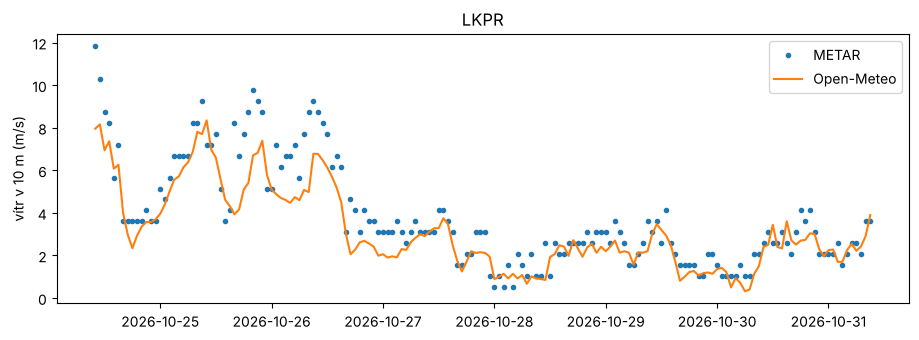

,hodin,vítr: odchylka modelu (m/s),vítr: RMSE (m/s),vítr: korelace,T: odchylka (°C),T: RMSE (°C),Td: odchylka (°C)
LKKV,168.0,-0.18,1.05,0.79,-0.08,0.94,-0.04
LKMT,168.0,-0.79,1.14,0.89,-0.04,0.92,0.38
LKPR,168.0,-0.67,1.17,0.93,-0.01,0.77,0.16
LKTB,168.0,-0.48,1.09,0.80,-0.34,0.93,-0.12


In [3]:
lats = ",".join(str(v[0]) for v in AIRPORTS.values()); lons = ",".join(str(v[1]) for v in AIRPORTS.values())
w = open_meteo({"latitude": lats, "longitude": lons, "past_days": 7, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "UTC",
                "hourly": "wind_speed_10m,wind_gusts_10m,temperature_2m,dew_point_2m"})
mod = pd.concat([pd.DataFrame(r["hourly"]).assign(stanice=k) for k, r in zip(AIRPORTS, w)])
mod["hodina"] = pd.to_datetime(mod["time"])
cmp = obs.merge(mod, on=["stanice", "hodina"])
rows = {}
for k, g in cmp.groupby("stanice"):
    rows[k] = {"hodin": len(g),
               "vítr: odchylka modelu (m/s)": (g.wind_speed_10m - g["vítr"]).mean(), "vítr: RMSE (m/s)": np.sqrt(((g.wind_speed_10m - g["vítr"]) ** 2).mean()),
               "vítr: korelace": g.wind_speed_10m.corr(g["vítr"]),
               "T: odchylka (°C)": (g.temperature_2m - g["T"]).mean(), "T: RMSE (°C)": np.sqrt(((g.temperature_2m - g["T"]) ** 2).mean()),
               "Td: odchylka (°C)": (g.dew_point_2m - g["Td"]).mean()}
k0 = list(AIRPORTS)[0]
g = cmp[cmp.stanice == k0]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(g.hodina, g["vítr"], ".", label="METAR"); ax.plot(g.hodina, g.wind_speed_10m, "-", label="Open-Meteo")
ax.set(ylabel="vítr v 10 m (m/s)", title=k0); ax.legend(); plt.show()
pd.DataFrame(rows).T.round(2)

> **✏️ Úkol 1.** Podhodnocuje model vítr, nebo ho nadhodnocuje? Jak velká je RMSE ve srovnání s typickou rychlostí větru na letišti? Na kterém letišti model sedí nejhůř a čím to může být (terén v okolí, údolí, rozlišení modelu)? Proč METAR udává vítr v celých uzlech a jakou chybu to samo o sobě přináší?

*Tvoje odpověď:* 

> **✏️ Úkol 2.** Jak přesně model trefuje teplotu a rosný bod? Odhad základny oblačnosti je 125 m na každý stupeň rozdílu T − Td: o kolik metrů se odhad posune, když se rosný bod splete o 1 °C? Co z toho plyne pro rozhodování o mlze, nízké oblačnosti a námraze podle modelu?

*Tvoje odpověď:* 

## 4. Profil větru a stabilita ovzduší

Vítr s výškou roste přibližně podle u(z) = u(10 m) · (z / 10)^α. Exponent α spočítáme z větru v 10 a 120 m pro každou hodinu za 92 dní a porovnáme ho s rozdílem teploty ve 120 a 2 m. Klesá-li teplota s výškou rychleji než o 1 °C na 100 m, je ovzduší labilní a promíchává se; roste-li s výškou (inverze), je stabilní.

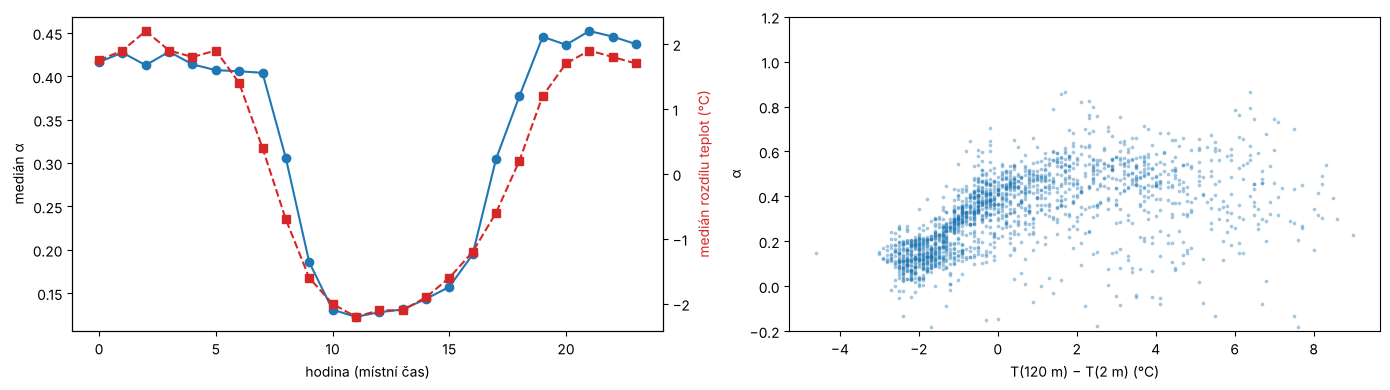

1799 hodin; suchoadiabatický pokles na 118 m je −1,15 °C


,hodin,alfa,vitr10,vitr120
stabilita,,,,
labilní (< −1 °C),628,0.16,2.60,3.98
slabě labilní,354,0.36,2.51,6.30
slabě stabilní,217,0.42,2.31,6.33
inverze (> +1 °C),600,0.46,0.92,3.09


In [4]:
LAT, LON = 50.152, 14.392            # ◀ parametr: místo letu (Roztoky)
w = open_meteo({"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "Europe/Prague",
                "hourly": "wind_speed_10m,wind_speed_80m,wind_speed_120m,wind_gusts_10m,temperature_2m,temperature_120m,dew_point_2m,precipitation,visibility"})
loc = pd.DataFrame(w["hourly"]); loc["time"] = pd.to_datetime(loc["time"]); loc = loc.set_index("time").dropna()
loc["alfa"] = np.log(loc.wind_speed_120m / loc.wind_speed_10m.clip(lower=0.5)) / np.log(120 / 10)   # exponent mocninného profilu
loc["dT"] = loc.temperature_120m - loc.temperature_2m                                               # teplota 120 m − 2 m
loc["stabilita"] = pd.cut(loc.dT, [-10, -1.0, 0.0, 1.0, 20], labels=["labilní (< −1 °C)", "slabě labilní", "slabě stabilní", "inverze (> +1 °C)"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
by_h = loc.groupby(loc.index.hour)
ax[0].plot(by_h.alfa.median(), "o-", label="exponent α"); ax2 = ax[0].twinx(); ax2.plot(by_h.dT.median(), "s--", color="C3", label="T(120 m) − T(2 m)")
ax[0].set(xlabel="hodina (místní čas)", ylabel="medián α"); ax2.set_ylabel("medián rozdílu teplot (°C)", color="C3")
ax[1].scatter(loc.dT, loc.alfa, s=3, alpha=0.3); ax[1].set(xlabel="T(120 m) − T(2 m) (°C)", ylabel="α", ylim=(-0.2, 1.2)); plt.tight_layout(); plt.show()
print(f"{len(loc)} hodin; suchoadiabatický pokles na 118 m je −1,15 °C")
loc.groupby("stabilita", observed=True).agg(hodin=("alfa", "size"), alfa=("alfa", "median"), vitr10=("wind_speed_10m", "median"), vitr120=("wind_speed_120m", "median")).round(2)

> **✏️ Úkol 3.** Proč je α v noci a ráno velké a přes den malé? Proč je při inverzi u země téměř bezvětří, zatímco ve 120 m fouká? Co to znamená, když ráno před vzletem změříš vítr ručním anemometrem a podle něj odhaduješ vítr ve výšce letu? V kolik hodin se inverze typicky rozpouští?

*Tvoje odpověď:* 

## 5. Létavé hodiny za poslední tři měsíce

Pro každou hodinu za 92 dní vyhodnotíme podmínky jako semafor v základní verzi: vítr ve 120 m, odhad nárazů ve 120 m, srážky, dohlednost a riziko námrazy. Nárazy ve 120 m model nedává, proto je odhadneme ze 10 m dvěma způsoby (`GUSTS`).

podíl denních hodin (6–20 h), kdy je podmínka splněna:
vítr 120 m      96.0
nárazy          65.5
bez srážek      90.7
dohlednost      95.4
bez námrazy    100.0
létat           58.0


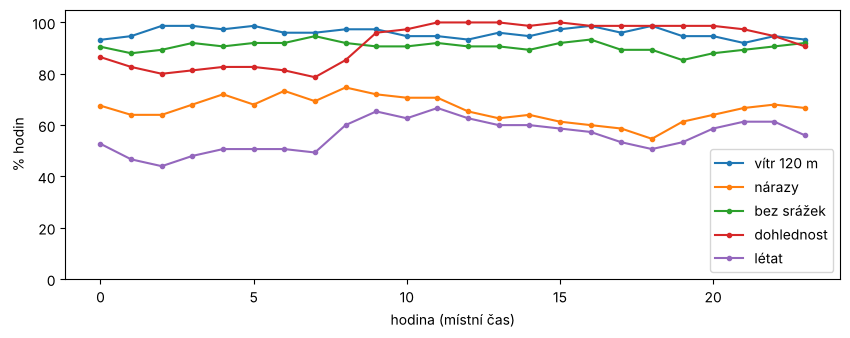

In [5]:
LIM_WIND, LIM_GUST = 10.0, 12.0      # ◀ parametr: limit větru ve 120 m a nárazů (m/s)
LIM_VIS = 5000                        # ◀ parametr: nejmenší dohlednost (m)
GUSTS = "poměr"                       # ◀ parametr: odhad nárazů ve 120 m: "poměr" (stejný poměr nárazy/vítr jako v 10 m) nebo "přírůstek" (stejný rozdíl)
if GUSTS == "poměr":
    gust120 = loc.wind_gusts_10m * loc.wind_speed_120m / loc.wind_speed_10m.clip(lower=0.5)
else:
    gust120 = loc.wind_speed_120m + (loc.wind_gusts_10m - loc.wind_speed_10m)
ok = pd.DataFrame({"vítr 120 m": loc.wind_speed_120m <= LIM_WIND, "nárazy": gust120 <= LIM_GUST, "bez srážek": loc.precipitation < 0.1,
                   "dohlednost": loc.visibility >= LIM_VIS, "bez námrazy": ~((loc.temperature_2m < 1) & (loc.temperature_2m - loc.dew_point_2m < 2))})
ok["létat"] = ok.all(axis=1)
day = ok[(ok.index.hour >= 6) & (ok.index.hour <= 20)]
print("podíl denních hodin (6–20 h), kdy je podmínka splněna:"); print((day.mean() * 100).round(1).to_string())
fig, ax = plt.subplots(figsize=(10, 3.5))
(ok.groupby(ok.index.hour).mean() * 100)[["vítr 120 m", "nárazy", "bez srážek", "dohlednost", "létat"]].plot(ax=ax, marker=".")
ax.set(xlabel="hodina (místní čas)", ylabel="% hodin", ylim=(0, 105)); plt.show()

> **✏️ Úkol 4.** Která podmínka v posledních třech měsících omezovala létání nejčastěji a ve kterou denní dobu byla šance na let nejlepší? Přepni `GUSTS` na druhý způsob odhadu nárazů: o kolik se změní podíl létavých hodin? Který odhad je podle tebe bližší skutečnosti a proč (jak se poryvy mění s výškou)?

*Tvoje odpověď:* 

> **✏️ Úkol 5.** Nastav limity pro menší dron (`LIM_WIND = 8`, `LIM_GUST = 10.7` jako odolnost DJI Mini 4 Pro) a pak pro přísnější provoz se snímkováním (dohlednost 8 km). Jak se změní podíl létavých hodin a jejich denní chod? Proč by tento výpočet pro zimní měsíce vyšel jinak?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Přidej do `AIRPORTS` letiště Linec (`"LOWL": (48.2332, 14.1875)`) nebo jiné a porovnej přesnost modelu. Změň `LAT, LON` na jiné místo letu (třeba Brno-Bystrc 49.2467, 16.4798) a porovnej profil větru a létavé hodiny.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- METAR: NOAA/NWS Aviation Weather Center, https://aviationweather.gov/data/api/ (veřejná data vlády USA).
- Počasí: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- Klíč ke zprávám METAR: ICAO Annex 3 / WMO-No. 306, kód FM 15.
- Stull, R. B. (1988). *An Introduction to Boundary Layer Meteorology*. Kluwer (denní chod mezní vrstvy, stabilita, profil větru).
- Odolnost DJI Mavic 3 Enterprise vůči větru 12 m/s a DJI Mini 4 Pro 10,7 m/s (technické listy DJI).

### Jak citovat

OpenSkyLab (2026). Můžu letět?, pokročilá verze: jak přesný je model, profil větru a létavé hodiny [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/drone_weather_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*